# Лабораторная работа № 5

## Конфигурационное пространство и прямая задача кинематики

**Дисциплина:** Введение в технологии виртуальной дополненной реальности и робототехники
**Тема курса:** 6. Конфигурационное пространство и прямая задача кинематики манипулятора

---

**Студент:** _фамилия, имя, группа_
**Дата:**

---

### Цель работы

Освоить два способа описания кинематической цепи — параметры Денавита — Хартенберга
и представление произведением экспонент, — убедиться в их эквивалентности,
и научиться оценивать рабочую зону манипулятора методом Монте-Карло.

### Что понадобится

`numpy`, `sympy`, `matplotlib`.

### Правило практикума

Алгоритм вы реализуете сами. Готовые пакеты робототехники (`roboticstoolbox`,
`spatialmath`) допустимо использовать **только** для сверки — и такую сверку
нужно показать явно.

## Теоретическая справка

### Кинематическая цепь и конфигурационное пространство

Манипулятор — цепь жёстких звеньев, соединённых сочленениями. Каждое вращательное
сочленение добавляет одну степень свободы, и набор всех углов $q = (q_1,\dots,q_n)$
задаёт **конфигурацию**.

Множество всех конфигураций называется конфигурационным пространством. Для цепи
из $n$ вращательных сочленений это тор $T^n = S^1 \times \dots \times S^1$: каждый
угол определён по модулю $2\pi$. Заметьте, что это не $\mathbb{R}^n$ — и по той же
причине, что обсуждалась в лекции 3, тор нельзя гладко и взаимно однозначно
отобразить на $\mathbb{R}^n$.

**Прямая задача кинематики** — это отображение

$$f:\ T^n \to SE(3), \qquad q \mapsto T(q),$$

сопоставляющее конфигурации позу схвата. Оно всегда однозначно и вычисляется явно;
обратное отображение неоднозначно и явной формулы в общем случае не имеет — этим
займёмся в теме 7.

### Параметры Денавита — Хартенберга

Переход между соседними звеньями задаётся четырьмя числами вместо шести: если
оси координат выбраны по специальному правилу, преобразование раскладывается в

$$T_i = R_z(\theta_i)\, T_z(d_i)\, T_x(a_i)\, R_x(\alpha_i).$$

Здесь $a_i$ — длина звена, $\alpha_i$ — угол скрещивания осей, $d_i$ — смещение
вдоль оси, $\theta_i$ — угол поворота. У вращательного сочленения переменная
величина — $\theta_i$, остальные три постоянны.

Полная кинематика — произведение вдоль цепи, ровно как дерево координат из лекции 2:

$$T(q) = T_1(q_1)\, T_2(q_2)\, \dots\, T_n(q_n).$$

### Представление произведением экспонент

Альтернатива, не требующая специального выбора осей. Каждому сочленению
сопоставляется винтовая ось $S_i = (\omega_i,\, v_i)$, где $\omega_i$ — единичный
вектор оси, а $v_i = -\omega_i \times q_i$ для точки $q_i$ на оси. Тогда

$$T(q) = e^{[S_1]q_1}\, e^{[S_2]q_2} \cdots e^{[S_n]q_n} \cdot M,$$

где $M$ — поза схвата в нулевой конфигурации. Матричная экспонента для $se(3)$
вычисляется в замкнутой форме — это прямое обобщение формулы Родрига из лекции 3.

### Рабочая зона и метод Монте-Карло

Рабочая зона — образ конфигурационного пространства при отображении $f$. Для
плоского 2R-манипулятора это кольцо с радиусами $|l_1 - l_2|$ и $l_1 + l_2$,
площадь которого равна $4\pi l_1 l_2$ — редкий случай, когда ответ известен точно
и с ним можно сверить численную оценку.

Метод Монте-Карло даёт погрешность порядка $N^{-1/2}$ независимо от размерности —
именно поэтому в шестимерном случае он остаётся практически единственным способом.

In [1]:
import sys

import numpy as np
import sympy as sp
import time
import matplotlib.pyplot as plt

import colors as c

from typing import Iterable, Collection, Callable, Any
from types import ModuleType

# промежуток для рандомных чисел векторов сдвига
SHIFT_MAX: int = 5
SHIFT_MIN: int = -SHIFT_MAX
SEED = 0

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(seed=SEED)

# константа как в UE5
SMALL_NUMBER = 1e-12

# ue_is_nearly_zero(val: float) -> bool -- копирка bool IsNearlyZero(float, float) из UE5
def ue_is_nearly_zero(val: float) -> bool: return abs(val) <= SMALL_NUMBER
def ue_is_nearly_equal(a: float, b: float) -> bool: return abs(a - b) <= SMALL_NUMBER
def ue_is_nearly_pi(val: float) -> bool: return abs(val - np.pi) <= 1e-4

def red(val) -> str: return f'{c.style(c.red)}{val}{c.style(c.clear)}'
def green(val) -> str: return f'{c.style(c.green)}{val}{c.style(c.clear)}'
def yellow(val) -> str: return f'{c.style(c.yellow)}{val}{c.style(c.clear)}'
def bold(val) -> str: return f'{c.style(c.bold)}{val}{c.style(c.clear)}'

def check(expr):
	return f'{bold(green('OK'))}' if expr else f'{bold(red('FAIL'))}'

# параметры UR5: (a, alpha, d) для шести звеньев, метры и радианы
def UR5(lib=np):
	return [(0.0,      lib.pi / 2,  0.089159),
			(-0.425,   0.0,        0.0),
			(-0.39225, 0.0,        0.0),
			(0.0,      lib.pi / 2,  0.10915),
			(0.0,     -lib.pi / 2,  0.09465),
			(0.0,      0.0,        0.0823)]


## Задание 1. Матрица Денавита — Хартенберга

Реализуйте `dh(a, alpha, d, theta, lib)` по формуле из справки. Параметр `lib`
позволит одной и той же функцией считать и численно (`numpy`), и символьно (`sympy`) —
это понадобится в заданиях 2 и 3.

**Контроль.** Для $a = 0{,}5$, $\alpha = 0$, $d = 0$, $\theta = 90°$ схват должен
оказаться в точке $(0;\ 0{,}5;\ 0)$. Проверьте также $\det R = 1$
и $\|R^{\mathsf T}R - I\|$ на уровне машинной погрешности.

**Вопрос для вывода:** почему для перехода между звеньями хватает четырёх чисел,
хотя элемент $SE(3)$ задаётся шестью?

In [2]:

def R_x(alpha: float, lib=np) -> sp.Matrix|np.ndarray:
	c = lib.cos(alpha)
	s = lib.sin(alpha)
	res = [
		[1, 0, 0, 0],
		[0, c, -s, 0],
		[0, s, c, 0],
		[0, 0, 0, 1]
	]
	return sp.Matrix(res) if lib is sp else np.asarray(res, dtype=float)

def R_z(alpha, lib=np) -> sp.Matrix|np.ndarray:
	c = lib.cos(alpha)
	s = lib.sin(alpha)
	res = [
		[c, -s, 0, 0],
		[s, c, 0, 0],
		[0, 0, 1, 0],
		[0, 0, 0, 1]
	]
	return sp.Matrix(res) if lib is sp else np.asarray(res, dtype=float)

def T_x(a, lib=np) -> sp.Matrix|np.ndarray:
	res = [
		[1, 0, 0, a],
		[0, 1, 0, 0],
		[0, 0, 1, 0],
		[0, 0, 0, 1]
	]
	return sp.Matrix(res) if lib is sp else np.asarray(res, dtype=float)

def T_z(a, lib=np) -> sp.Matrix|np.ndarray:
	res = [
		[1, 0, 0, 0],
		[0, 1, 0, 0],
		[0, 0, 1, a],
		[0, 0, 0, 1]
	]
	return sp.Matrix(res) if lib is sp else np.asarray(res, dtype=float)

def dh_old(a, alpha, d, theta, lib=np) -> sp.Matrix|np.ndarray:
	return R_z(theta, lib) @ T_z(d, lib) @ T_x(a, lib) @ R_x(alpha, lib)

def dh(a, alpha, d, theta, lib=np) -> sp.Matrix|np.ndarray:
	# res = R_z(theta, lib) @ T_z(d, lib) @ T_x(a, lib) @ R_x(alpha, lib)
	ct, st = lib.cos(theta), lib.sin(theta)
	ca, sa = lib.cos(alpha), lib.sin(alpha)
	res = [[ct, -st*ca,  st*sa, a*ct],
			[st,  ct*ca, -ct*sa, a*st],
			[0,   sa,     ca,    d   ],
			[0,   0,      0,     1   ]]
	return sp.Matrix(res) if lib is sp else np.asarray(res, dtype=float)

def __task_1(lib=np):
	print(f'{yellow('Используется')} {green(lib.__name__)}')
	T = dh(0.5, 0, 0, lib.pi/2, lib)
	R = T[:3, :3]
	t = T[:3, 3]

	if lib is np:
		R = np.array(R)
	else:
		R = sp.Matrix(R)

	p_exp = np.array([0., 0.5, 0.])
	print(f'Ожидаемое значение {p_exp}, получено {t}')
	
	det_func = np.linalg.det if lib is np else sp.det
	det_R: float = float(det_func(R))
	print(f'{bold('R')} = {R}')

	print(f'{bold('det(R)')} = {det_R}\t\t=> {check(ue_is_nearly_equal(det_R, 1))}')
	
	norm_func = np.linalg.norm if lib is np else sp.Matrix.norm
	difference = norm_func(R.T @ R - lib.eye(3))
	print(f'{c.style(c.bold)}||R.T @ R - E||{c.style(c.clear)} = {difference}\t=> {check(ue_is_nearly_zero(difference))}')
	print()

def task_1():
	__task_1(np)
	__task_1(sp)

task_1()

Используется numpy
Ожидаемое значение [0.  0.5 0. ], получено [0.  0.5 0. ]
R = [[ 0. -1.  0.]
 [ 1.  0. -0.]
 [ 0.  0.  1.]]
det(R) = 1.0		=> OK
||R.T @ R - E|| = 0.0	=> OK

Используется sympy
Ожидаемое значение [0.  0.5 0. ], получено Matrix([[0], [0.500000000000000], [0]])
R = Matrix([[0, -1, 0], [1, 0, 0], [0, 0, 1]])
det(R) = 1.0		=> OK
||R.T @ R - E|| = 0	=> OK



## Задание 2. Плоский 3R символьно

Средствами SymPy перемножьте три матрицы DH с символьными длинами $l_1, l_2, l_3$
и углами $q_1, q_2, q_3$. Извлеките координаты схвата и упростите их.

Сверьте с формулой, которую нетрудно получить вручную из чертежа:

$$x = l_1\cos q_1 + l_2\cos(q_1{+}q_2) + l_3\cos(q_1{+}q_2{+}q_3).$$

Извлеките также ориентацию схвата через `atan2` от элементов матрицы поворота.

**Контроль.** `simplify(x_sym - x_ref) == 0` для обеих координат.

**Вопрос для вывода:** чему равна ориентация схвата и почему ответ выглядит именно
так для плоской цепи?

In [3]:

def task_2():
	l1, l2, l3, q1, q2, q3 = sp.symbols('l1 l2 l3 q1 q2 q3', real=True)

	T = dh(l1, 0, 0, q1, sp) @ dh(l2, 0, 0, q2, sp) @ dh(l3, 0, 0, q3, sp)
	x_sym = sp.simplify(T[0,3])
	y_sym = sp.simplify(T[1,3])
	print(f'{c.style(c.yellow)}Вычислено с помощью SymPy{c.style(c.clear)}')
	print('x =', x_sym)
	print('y =', y_sym)

	# x связан с cos
	# y связан с sin
	x_ref = l1*sp.cos(q1) + l2*sp.cos(q1 + q2) + l3*sp.cos(q1 + q2 + q3)
	y_ref = l1*sp.sin(q1) + l2*sp.sin(q1 + q2) + l3*sp.sin(q1 + q2 + q3)
	
	print(f'\n{c.style(c.yellow)}Референсные формулы из шаблона{c.style(c.clear)}')
	print('x_ref =', x_ref)
	print('y_ref =', y_ref)

	chck_x = sp.simplify(x_sym - x_ref)
	chck_y = sp.simplify(y_sym - y_ref)

	print(f'\n{c.style(c.yellow)}Сверка результатов. Должно равняться нулю{c.style(c.clear)}')
	print(f'x - x_ref = {chck_x}\t=> {check(float(chck_x) == 0)}')
	print(f'y - y_ref = {chck_y}\t=> {check(float(chck_y) == 0)}')

	x_rot = T[0,0] # должно быть cos
	y_rot = T[1,0] # должно быть sin
	orient = sp.atan2(y_rot, x_rot) # atan2(sin(a), cos(a))

	print(f'\n{yellow('Ориентация схвата')}')
	print(f'x = {sp.simplify(x_rot)}')
	print(f'y = {sp.simplify(y_rot)}')
	print(f'ориентация схвата = {sp.simplify(orient)}')
	
task_2()

Вычислено с помощью SymPy
x = l1*cos(q1) + l2*cos(q1 + q2) + l3*cos(q1 + q2 + q3)
y = l1*sin(q1) + l2*sin(q1 + q2) + l3*sin(q1 + q2 + q3)

Референсные формулы из шаблона
x_ref = l1*cos(q1) + l2*cos(q1 + q2) + l3*cos(q1 + q2 + q3)
y_ref = l1*sin(q1) + l2*sin(q1 + q2) + l3*sin(q1 + q2 + q3)

Сверка результатов. Должно равняться нулю
x - x_ref = 0	=> OK
y - y_ref = 0	=> OK

Ориентация схвата
x = cos(q1 + q2 + q3)
y = sin(q1 + q2 + q3)
ориентация схвата = atan2(sin(q1 + q2 + q3), cos(q1 + q2 + q3))


## Задание 3. Промышленный манипулятор UR5 и компиляция выражения

В таблице `UR5` заданы реальные параметры шестиосевого манипулятора Universal
Robots UR5. Постройте прямую кинематику двумя путями: численным циклом по матрицам
и символьным произведением с последующей компиляцией через `lambdify`.

Углы скрещивания $\alpha$ задавайте **точными** значениями (`sp.pi/2`), а не числами
с плавающей точкой: тогда синусы и косинусы схлопнутся в $0$ и $\pm1$, и выражение
сократится вдвое.

Сравните время счёта четырёх вариантов: `subs` + `evalf`, `lambdify`,
`lambdify` с исключением общих подвыражений (`cse=True`) и рукописный numpy-цикл.

Затем возьмите 20000 случайных конфигураций, постройте облако положений схвата
и оцените максимальный вылет. Сравните его с оценкой сверху по неравенству
треугольника — суммой всех переносов вдоль цепи.

**Контроль.** Оба способа дают одинаковый результат с точностью $10^{-12}$;
`cse` даёт ускорение не менее чем в 50 раз; измеренный вылет лежит между
$a_2 + a_3$ и оценкой сверху.

**Вопросы для вывода:** во сколько раз ускоряет `cse` и почему так сильно? Обгоняет
ли скомпилированное выражение рукописный numpy-цикл, и если да — почему?

In [4]:
# возвращает время выполнения функции n-ое количество раз в микросекундах
def timer(func: Callable, count: int = 1) -> int:
	t = time.perf_counter_ns()
	for i in range(count):
		func()
	return (time.perf_counter_ns() - t) // 1000

# численный и символьный способы построения кинематики
# т.е. через методы numpy и sympy
# 2 в 1
def forward_kinematic(lib: ModuleType = np, angles: Iterable|Any|None = None) -> sp.Matrix|np.ndarray:
	assert angles is not None, TypeError

	T = lib.eye(4)
	for (a, alpha, d), th in zip(UR5(np), angles):
		T = T @ dh(a, alpha, d, th, lib)
	return sp.Matrix(T) if lib is sp else np.array(T)


def task_3():
	angles_sp = sp.symbols('q1 q2 q3 q4 q5 q6', real=True)

	fk_num_time = timer(lambda: forward_kinematic(np, [1,0,6,0,0,0]))
	fk_sym_time = timer(lambda: forward_kinematic(sp, angles_sp))
	
	print(yellow('Скорость создания матриц кинематики'))
	print(f'num\t{c.style(c.green)}{fk_num_time} мкс{c.style(c.clear)}')
	print(f'sym\t{c.style(c.green)}{fk_sym_time} мкс{c.style(c.clear)}')
	print(f'numsym\t{c.style(c.green)}{(f'{(fk_sym_time / fk_num_time):.2f}')}{c.style(c.clear)}')

	f_lamdify = sp.lambdify(angles_sp, forward_kinematic(sp, angles_sp), 'numpy', cse=False)
	f_cse = sp.lambdify(angles_sp, forward_kinematic(sp, angles_sp), 'numpy', cse=True)

	angles_np = rng.uniform(-np.pi, np.pi, 6)

	A = forward_kinematic(np, angles_np)
	B = np.array(f_lamdify(*angles_np), dtype=float)
	C = np.array(f_cse(*angles_np), dtype=float)

	delta_lambda = np.abs(A - B).max()
	delta_cse = np.abs(A - C).max()
	print(yellow('\nПроверка ошибок'))
	print(f'num - lambdify\t{c.style(c.green)}{delta_lambda:.2e}{c.style(c.clear)}\t=> {check(ue_is_nearly_zero(delta_lambda))}')
	print(f'num - cse\t{c.style(c.green)}{delta_cse:.2e}{c.style(c.clear)}\t=> {check(ue_is_nearly_zero(delta_cse))}')

	T_sp: sp.Matrix = sp.Matrix(forward_kinematic(sp, angles_sp))
	sub = dict(zip(angles_sp, angles_np))
	time_subs = timer(lambda: np.array(T_sp.subs(sub).evalf(), dtype=float))
	time_lambda = timer(lambda: f_lamdify(*angles_np))
	time_cse = timer(lambda: f_cse(*angles_np))
	time_loop = timer(lambda: forward_kinematic(np, angles_np))

	print(yellow('\nЗамер скоростей работы'))
	print(f'{c.style(c.bold)}{'метод':16s}{'мс':10s}{'ускорение'}{c.style(c.clear)}')
	for name, time in [
			('subs + evalf', time_subs),
			('lambda', time_lambda),
			('cse', time_cse),
			('numpy-loop', time_loop)]:
		print(f'{name:16s}{str(time):10s}{(time_subs/time):.2f}')

	N = 20000
	Q = rng.uniform(-np.pi, np.pi, (N, 6))
	P = np.array([np.array(f_cse(*q), dtype=float)[:3, 3] for q in Q])

	reach = np.linalg.norm(P, axis=1).max()
	upper = sum(np.hypot(a, d) for a, i, d in UR5(np))
	lower = abs(UR5(np)[1][0]) + abs(UR5(np)[2][0])

	print(yellow('\nОблако точек'))
	print(f'a2 + a3\t\t\t{lower:.4f} м')
	print(f'измеренный вылет\t{reach:.4f} м')
	print(f'оценка сверху\t\t{upper:.4f} м')
	print(f'лежит между границами => {check(lower < reach < upper)}')

task_3()

Скорость создания матриц кинематики
num	134 мкс
sym	48145 мкс
numsym	359.29

Проверка ошибок
num - lambdify	1.39e-16	=> OK
num - cse	1.11e-16	=> OK

Замер скоростей работы
метод           мс        ускорение
subs + evalf    63951     1.00
lambda          273       234.25
cse             23        2780.48
numpy-loop      65        983.86

Облако точек
a2 + a3			0.8173 м
измеренный вылет	1.0340 м
оценка сверху		1.1925 м
лежит между границами => OK


## Задание 4. Рабочая зона плоского 2R и сходимость Монте-Карло

Для $l_1 = 0{,}5$, $l_2 = 0{,}35$ вычислите точную площадь кольца.
Затем оцените её методом Монте-Карло: бросайте точки в квадрат со стороной
$2(l_1{+}l_2)$ и считайте долю попавших в кольцо.

Для $N$ от $10^2$ до $10^6$ усредните ошибку по 30 независимым запускам, постройте
график в двойном логарифмическом масштабе и оцените наклон.

**Контроль.** Наклон должен получиться близким к $-0{,}5$.

**Вопросы для вывода:** почему точная площадь равна $4\pi l_1 l_2$? Во сколько раз
надо увеличить $N$, чтобы уменьшить ошибку вдвое? Зависит ли скорость сходимости
от размерности задачи?

l1 = 0.5, l2 = 0.35
Площадь кольца по формуле:		2.199115
Наклон = -0.5073702519017222


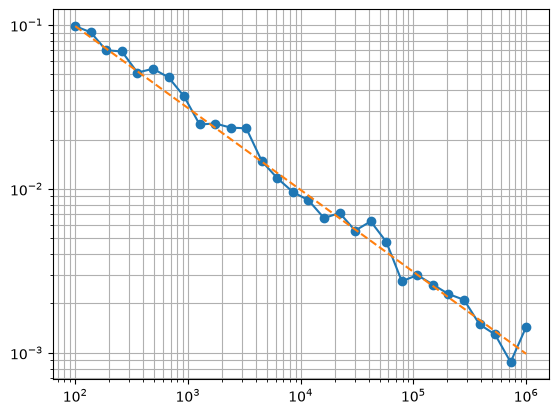

In [ ]:

# площадь кольца, указанного через l1 и l2
# где r1 = |l1 - l2|, r2 = l1 + l2
# pi*(l1+l2)^2 - pi*(l1-l2)^2 => pi*((l1+l2)^2 - (l1-l2)^2) => 4*pi*l1*l2
def calc_ring_area(l1: float, l2: float) -> float:
	return np.pi * (4 * l1 * l2)

def monte_carlo_area(l1: float, l2: float, points_count: int) -> float:
	r_out = l1+l2
	r_in = abs(l1-l2)
	
	x = np.random.uniform(-r_out, r_out, points_count)
	y = np.random.uniform(-r_out, r_out, points_count)

	dist_square = x*x + y*y
	inside = (dist_square >= r_in*r_in) &  (dist_square <= r_out*r_out)
	return 4*r_out*r_out * np.mean(inside)

	
def task_4():
	steps = 30
	l1, l2 = 0.5, 0.35
	print(f'l1 = {l1}, l2 = {l2}')
	print(f'Площадь кольца по формуле:\t{calc_ring_area(0.5, 0.35):.6f}')

	numbers = np.logspace(2, 6, steps).astype(int)
	errs = [np.mean([abs(monte_carlo_area(l1, l2, N) - calc_ring_area(l1,l2)) for _ in range(steps)]) for N in numbers]
	slope = np.polyfit(np.log10(numbers), np.log10(errs), 1)[0]
	print(f'Наклон = {slope}')

	plt.loglog(numbers, errs, 'o-', label='ошибка (среднее по 30 запускам)')
	plt.loglog(numbers, errs[0] * (numbers / numbers[0])**-0.5, '--', label='N^(-1/2)')
	plt.grid(visible=True, which='both')
	plt.show()

task_4()

## Задание 5. Объём рабочей зоны UR5

Для шестиосевого манипулятора точной формулы нет. Оцените объём рабочей зоны
по облаку точек: разбейте пространство на воксели со стороной $h$ и умножьте число
занятых вокселей на $h^3$.

Посчитайте оценку при $h = 0{,}08$, $0{,}05$, $0{,}03$ м, а затем при фиксированном
$h = 0{,}05$ проследите, как оценка меняется с ростом числа выборок.

**Контроль.** Оценка должна расти с числом выборок.

**Вопросы для вывода:** почему оценка растёт с $N$ и не выходит на плато даже
при 20000 выборок? Почему она так сильно зависит от $h$? В какую сторону смещена
такая оценка и почему? Сколько примерно выборок нужно, чтобы заполнить все воксели
при $h = 0{,}05$?

In [6]:
def voxel_volume(points, h):
	indices = np.floor(points / h).astype(int)
	found = len(np.unique(indices, axis=0))
	return found * (h ** 3)

def task_5():
	angles_sp = sp.symbols('q1 q2 q3 q4 q5 q6', real=True)
	f_cse = sp.lambdify(angles_sp, forward_kinematic(sp, angles_sp), 'numpy', cse=True)

	N = 20000
	angles = rng.uniform(-np.pi, np.pi, (N, 6))
	points = np.array([np.array(f_cse(*a), dtype=float)[:3,3] for a in angles])

	print(yellow('Проверка зависимости объема от значения h'))
	for h in (0.08, 0.05, 0.03):
		print(f'h = {h}\tV = {voxel_volume(points, h):.4f}')

	print(yellow('\nПроврека зависимости объема от числа точек при h = 0.05'))
	for n in np.linspace(100, N, 5, dtype=int):
		print(f'n = {n}\tV = {voxel_volume(points[:n], 0.05):.8f}')

task_5()

Проверка зависимости объема от значения h
h = 0.08	V = 2.9112
h = 0.05	V = 1.4664
h = 0.03	V = 0.4563

Проврека зависимости объема от числа точек при h = 0.05
n = 100	V = 0.01250000
n = 5075	V = 0.52437500
n = 10050	V = 0.90925000
n = 15025	V = 1.21412500
n = 20000	V = 1.46637500


## Задание 6. Произведение экспонент и его эквивалентность DH

Реализуйте `exp_se3(S, theta)` — матричную экспоненту для винтовой оси.
Формула прямо обобщает Родрига из лекции 3:

$$e^{[S]\theta} = \begin{pmatrix} e^{[\omega]\theta} & G(\theta)\,v \\ 0 & 1\end{pmatrix},
\quad G(\theta) = I\theta + (1-\cos\theta)[\omega] + (\theta - \sin\theta)[\omega]^2 .$$

Задайте для плоского 3R матрицу $M$ нулевой конфигурации и три винтовые оси,
после чего сравните результат с DH-версией на 500 случайных конфигурациях.

**Контроль.** Расхождение на уровне машинной погрешности ($\sim 10^{-16}$).

**Вопрос для вывода:** в чём преимущество представления произведением экспонент
перед DH, если результат тот же?

In [7]:
# TODO: задание 6

## Задание 7. Движение по последовательности конфигураций

Постройте функцию `arm_points(q)`, возвращающую координаты всех сочленений
плоского 3R. Задайте линейную интерполяцию между двумя конфигурациями по 60 шагам
и нарисуйте несколько промежуточных поз с нарастающей непрозрачностью, а поверх —
траекторию схвата.

**Вопрос для вывода:** траектория схвата при линейной интерполяции в конфигурационном
пространстве — прямая линия в рабочем пространстве? Почему?

In [8]:
# TODO: задание 7

## Выводы

_Ответьте на все вопросы, отмеченные как «вопрос для вывода», приводя конкретные числа._

## Контрольные вопросы

1. Что такое конфигурационное пространство? Почему для цепи из $n$ вращательных
   сочленений это тор $T^n$, а не $\mathbb{R}^n$?
2. Почему прямая задача кинематики всегда разрешима однозначно, а обратная — нет?
3. Какой геометрический смысл у каждого из четырёх параметров DH?
4. Почему для перехода между соседними звеньями хватает четырёх чисел вместо шести?
5. В чём недостатки соглашения DH и что предлагает взамен представление
   произведением экспонент?
6. Запишите формулу винтовой оси $S = (\omega, v)$ для вращательного сочленения.
   Каков геометрический смысл вектора $v$?
7. Как связаны формула Родрига из лекции 3 и матричная экспонента для $se(3)$?
8. Что такое рабочая зона? Чему равна её площадь для плоского 2R-манипулятора?
9. Почему погрешность метода Монте-Карло убывает как $N^{-1/2}$ и не зависит
   от размерности?
10. Почему воксельная оценка объёма смещена вниз и как это исправить?